# Tomorrow's Connecticut electricity demand, from four weather models

**Dr. Dave · University of Connecticut** · demo, October 2026

A load model only knows about weather if you give it a weather forecast. This notebook:
1. **Trains** a simple model on three years of Connecticut load and the weather that actually happened (2023-2025).
2. **Downloads today's forecast for tomorrow** at Bradley Airport from four weather models with
   [hefty](https://github.com/williamhobbs/hefty) (Will Hobbs, Southern Company):

| model | who runs it | what it is |
|---|---|---|
| `hrrr` | NOAA | High-Resolution Rapid Refresh: 3 km grid, U.S. only, new run every hour |
| `gfs` | NOAA | Global Forecast System: the U.S. global model, 25 km |
| `ifs` | ECMWF | "the Euro": the European global model |
| `aifs` | ECMWF | the European **machine-learning** weather model (a neural network trained on decades of weather) |

3. **Predicts tomorrow, hour by hour,** once per weather model, plus once with no weather at all.

The students don't train GFS or the Euro - NOAA and ECMWF run those on supercomputers. Students train the **load** model, and
the weather models supply its inputs. Where the four forecasts disagree, that spread is a free measure of uncertainty.

Runtime -> Run all (about 3 minutes; no keys needed).

## Setup
`hefty` needs Python 3.12 or newer (Colab has it). If Colab asks to restart after the install, click **Restart**, then **Run all**.

In [1]:
try:
    import hefty
    print('hefty already installed')
except ImportError:
    !pip install -q hefty

hefty already installed


In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib
from hefty.solar import get_solar_forecast
from hefty.utilities import adjust_forecast_datetimes
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

In [3]:
SETTINGS = {
    'site': 'Bradley Airport (BDL)',
    'latitude': 41.9389,
    'longitude': -72.6832,
    'weather_models': ['hrrr', 'gfs', 'ifs', 'aifs'],
    'load_url': 'https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/bdl_ct_load_hourly_2023_2025.csv',
    'seed': 5509,
}
SETTINGS

{'site': 'Bradley Airport (BDL)',
 'latitude': 41.9389,
 'longitude': -72.6832,
 'weather_models': ['hrrr', 'gfs', 'ifs', 'aifs'],
 'load_url': 'https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/bdl_ct_load_hourly_2023_2025.csv',
 'seed': 5509}

## Step 1: train on three years of history
Inputs: the clock (hour, day of week, month) and the weather Bradley actually measured - temperature, and sunlight (a clear sky's
sunlight from pvlib, dimmed by the reported cloud cover). The same tree is also trained on the clock alone, for comparison.

In [4]:
load = pd.read_csv(SETTINGS['load_url'])
load['hour_utc'] = pd.to_datetime(load['hour_utc'], utc=True)
load = load.set_index('hour_utc')
local = load.index.tz_convert('America/New_York')
load['hour_local'] = local.hour
load['day_of_week'] = local.dayofweek
load['month'] = local.month
site = pvlib.location.Location(SETTINGS['latitude'], SETTINGS['longitude'])
load['ghi_clear'] = site.get_clearsky(load.index + pd.Timedelta(minutes=30), model='ineichen')['ghi'].values
load['sun'] = load['ghi_clear'] * (1 - 0.75 * (load['cloud_cover_pct'] / 100) ** 3.4)
load = load.dropna(subset=['sun'])
print('training data:', load.shape, load.index.min(), '->', load.index.max())

CLOCK = ['hour_local', 'day_of_week', 'month']
WITH_WEATHER = CLOCK + ['temp_f', 'sun']
tree_clock = DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=SETTINGS['seed'])
tree_clock.fit(load[CLOCK], load['load_mw'])
tree_weather = DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=SETTINGS['seed'])
tree_weather.fit(load[WITH_WEATHER], load['load_mw'])
print('X with weather:', load[WITH_WEATHER].shape, '| X clock only:', load[CLOCK].shape)

training data: (26304, 21) 2023-01-01 05:00:00+00:00 -> 2026-01-01 04:00:00+00:00


X with weather: (26304, 5) | X clock only: (26304, 3)


## Step 2: today's forecasts for tomorrow
`adjust_forecast_datetimes` picks the newest run of each model that has actually been published by now (the Euro runs are
published later than NOAA's, so they are often a few hours older).

In [5]:
now = pd.Timestamp.now(tz='UTC').floor('h').tz_localize(None)
tomorrow = pd.Timestamp.now(tz='America/New_York').normalize() + pd.Timedelta(days=1)
hours = pd.date_range(tomorrow.tz_convert('UTC'), periods=24, freq='h')
lead = int((hours[0].tz_localize(None) - now) / pd.Timedelta(hours=1))
print('now:', now, 'UTC | tomorrow =', tomorrow.date(), '| first hour is', lead, 'hours away')

forecasts = {}
for model in SETTINGS['weather_models']:
    t0 = time.time()
    init, run_length, lead_start = adjust_forecast_datetimes(now, 24, lead, model=model)
    f = get_solar_forecast(SETTINGS['latitude'], SETTINGS['longitude'], init,
                           run_length=run_length, lead_time_to_start=lead_start, model=model)
    f.index = f.index.floor('h')
    f = f[~f.index.duplicated()].reindex(hours)
    forecasts[model] = f
    print(f'{model:5s} run issued {init:%b %d %H:%M} UTC | shape {f.shape} | {round(time.time() - t0)} s')

now: 2026-10-16 19:00:00 UTC | tomorrow = 2026-10-17 | first hour is 9 hours away


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2026-Oct-16 12:00 UTC F16 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2026-Oct-16 12:00 UTC F17 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


...

✅ Found ┊ model=aifs ┊ product=oper ┊ 2026-Oct-16 12:00 UTC F36 ┊ GRIB2 @ google ┊ IDX @ google


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


✅ Found ┊ model=aifs ┊ product=oper ┊ 2026-Oct-16 12:00 UTC F42 ┊ GRIB2 @ google ┊ IDX @ google


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


aifs  run issued Oct 16 12:00 UTC | shape (24, 10) | 14 s


In [6]:
temps = pd.DataFrame(index=hours.tz_convert('America/New_York'))
for model in forecasts:
    temps[model] = forecasts[model]['temp_air'].values * 9 / 5 + 32
print('tomorrow\'s forecast temperature at Bradley (°F):')
temps.round(0)

tomorrow's forecast temperature at Bradley (°F):


,hrrr,gfs,ifs,aifs
2026-10-17 00:00:00-04:00,53.0,52.0,54.0,55.0
2026-10-17 01:00:00-04:00,52.0,50.0,53.0,53.0
2026-10-17 02:00:00-04:00,50.0,48.0,52.0,52.0
2026-10-17 03:00:00-04:00,48.0,47.0,51.0,51.0
2026-10-17 04:00:00-04:00,47.0,46.0,50.0,50.0
2026-10-17 05:00:00-04:00,46.0,46.0,49.0,49.0
2026-10-17 06:00:00-04:00,46.0,44.0,48.0,48.0
2026-10-17 07:00:00-04:00,46.0,43.0,47.0,47.0
2026-10-17 08:00:00-04:00,45.0,44.0,47.0,46.0
2026-10-17 09:00:00-04:00,45.0,44.0,48.0,47.0


## Step 3: predict tomorrow's load
Same trained tree, fed each weather model's forecast in turn - then the four predictions averaged hour by hour (an **ensemble**).

In [7]:
local_hours = hours.tz_convert('America/New_York')
X = pd.DataFrame({'hour_local': local_hours.hour, 'day_of_week': local_hours.dayofweek, 'month': local_hours.month}, index=hours)

predictions = pd.DataFrame(index=local_hours)
predictions['no weather'] = tree_clock.predict(X[CLOCK])
for model in forecasts:
    X_model = X.copy()
    X_model['temp_f'] = forecasts[model]['temp_air'].values * 9 / 5 + 32
    X_model['sun'] = forecasts[model]['ghi'].values
    predictions[model] = tree_weather.predict(X_model[WITH_WEATHER])

# the ensemble: average the four weather-model predictions hour by hour
predictions['average of 4'] = predictions[SETTINGS['weather_models']].mean(axis=1)
print('predictions:', predictions.shape)
predictions.round(0)

predictions: (24, 6)


,no weather,hrrr,gfs,ifs,aifs,average of 4
2026-10-17 00:00:00-04:00,2236.0,2128.0,2128.0,2128.0,2128.0,2128.0
2026-10-17 01:00:00-04:00,2097.0,2128.0,2128.0,2128.0,2128.0,2128.0
2026-10-17 02:00:00-04:00,2097.0,2128.0,2128.0,2128.0,2128.0,2128.0
2026-10-17 03:00:00-04:00,2097.0,2128.0,2128.0,2128.0,2128.0,2128.0
2026-10-17 04:00:00-04:00,2097.0,2128.0,2128.0,2128.0,2128.0,2128.0
2026-10-17 05:00:00-04:00,2074.0,2244.0,2244.0,2244.0,2244.0,2244.0
2026-10-17 06:00:00-04:00,2313.0,2320.0,2320.0,2320.0,2320.0,2320.0
2026-10-17 07:00:00-04:00,2478.0,2320.0,2320.0,2320.0,2320.0,2320.0
2026-10-17 08:00:00-04:00,2478.0,2574.0,2574.0,2574.0,2574.0,2574.0
2026-10-17 09:00:00-04:00,2478.0,2574.0,2574.0,2574.0,2574.0,2574.0


In [8]:
summary = pd.DataFrame({'peak (MW)': predictions.max(), 'peak hour': predictions.idxmax().dt.strftime('%I %p'),
                        'whole day (MWh)': predictions.sum()})
summary.round(0)

,peak (MW),peak hour,whole day (MWh)
no weather,2913.0,04 PM,59464.0
hrrr,3536.0,07 PM,62734.0
gfs,3386.0,05 PM,62948.0
ifs,3386.0,06 PM,61613.0
aifs,3386.0,05 PM,62821.0
average of 4,3423.0,07 PM,62529.0


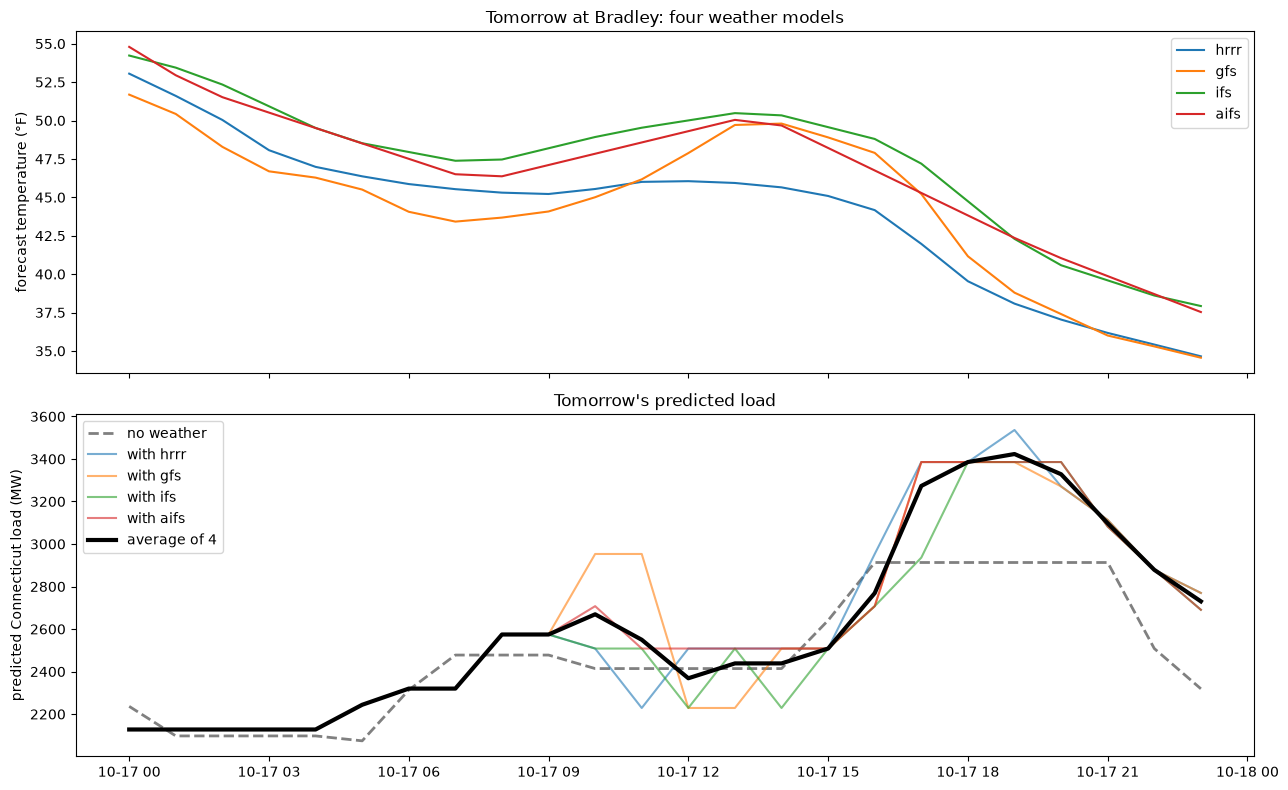

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for model in forecasts:
    axes[0].plot(temps.index, temps[model], label=model)
axes[0].set_ylabel('forecast temperature (°F)')
axes[0].legend()
axes[0].set_title('Tomorrow at Bradley: four weather models')
axes[1].plot(predictions.index, predictions['no weather'], color='grey', linestyle='--', linewidth=2, label='no weather')
for model in forecasts:
    axes[1].plot(predictions.index, predictions[model], label='with ' + model, alpha=0.6)
axes[1].plot(predictions.index, predictions['average of 4'], color='black', linewidth=3, label='average of 4')
axes[1].set_ylabel('predicted Connecticut load (MW)')
axes[1].legend()
axes[1].set_title('Tomorrow\'s predicted load')
plt.tight_layout()
plt.show()

## What to look at
- **Gap between "no weather" and the rest:** that is what the forecast is worth tomorrow. On an ordinary day it is small; ahead of
  a cold snap or a heat wave it is hundreds of MW.
- **Spread between the four weather models:** when they agree, trust the forecast more; when they don't, the truth is uncertain.
  A simple, strong trick is to average them (an "ensemble").
- **Backtest, not one day:** whether HRRR or the Euro makes the better *load* forecast is a question for a month or a year of
  past forecasts (see `hefty_one_month_test.ipynb`: in July 2025 the HRRR forecast cut the load error from 410 MW to 287 MW).
- **Check tomorrow:** ISO New England posts the actual Connecticut load (ISO Express, zonal information) - compare it with the lines above.

Ideas for students: train separate models per weather model, average the four predictions, use a gradient-boosted tree or an
LSTM instead of a single decision tree, or add ISO-NE's own day-ahead solar forecast as an input.